# 🔬 Concept Drift PoC — CICIDS2017 + River (Online Learning)
---
**Objetivo**: Demostrar cómo un modelo estático degrada su rendimiento ante *concept drift*,
mientras que un modelo reactivo (con PHT) se adapta dinámicamente.

| Fase | Modelo | Estrategia |
|------|--------|------------|
| A | Hoeffding Adaptive Tree | Pre-entrenamiento → solo predicción (sin actualización) |
| B | Hoeffding Adaptive Tree + PHT | Pre-entrenamiento → Test-then-Train adaptativo con detección de drift |


In [1]:
import time
# ════════════════════════════════════════════════════════════════
# 📦  Imports
# ════════════════════════════════════════════════════════════════
import csv
import math
import copy
import warnings
from collections import Counter, deque

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

from river import tree, drift, metrics

warnings.filterwarnings("ignore")

print("✅ Imports cargados correctamente")

✅ Imports cargados correctamente


In [2]:
# ════════════════════════════════════════════════════════════════
# ⚙️  Configuración del Experimento
# ════════════════════════════════════════════════════════════════

CSV_PATH = "/mnt/AI-DATA-SSD/alara/Data/CIC-IDS2017.csv"

# Columnas a descartar (sin valor algorítmico para el árbol)
DROP_COLS = {"Flow ID", "Source IP", "Destination IP", "Timestamp"}

# Nombre de la columna objetivo
TARGET_COL = "Attack Type"

# Para evitar el largo bloque inicial de solo tráfico BENIGN, empezamos en la fila 500,000.
# Así las primeras ~40,000 muestras serán benignas (ideal para pre-entrenamiento)
# y a partir de-000 la 541,233 aparecerán ataques (Brute Force), provocando el drift.
START_ROW = 540_000

# Número de muestras para pre-entrenamiento (dentro del stream iniciado en START_ROW)
N_PRETRAIN = 50_000

# Número máximo de muestras a procesar a partir de START_ROW
MAX_SAMPLES = 2_000_000

# Parámetros de logs y snapshots
LOG_INTERVAL   = 10_000
SNAP_INTERVAL  = 500

print(f"📂 Dataset: {CSV_PATH}")
print(f"🔄 Fila de inicio: {START_ROW:,}")
print(f"🎯 Muestras de pre-entrenamiento: {N_PRETRAIN:,}")
print(f"📊 Muestras máximas a procesar: {MAX_SAMPLES:,}")

📂 Dataset: /mnt/AI-DATA-SSD/alara/Data/CIC-IDS2017.csv
🔄 Fila de inicio: 540,000
🎯 Muestras de pre-entrenamiento: 50,000
📊 Muestras máximas a procesar: 2,000,000


In [3]:
# ════════════════════════════════════════════════════════════════
# 🔧  Funciones de Preprocesamiento y Stream
# ════════════════════════════════════════════════════════════════

def preprocess_row(row: dict, drop_cols: set, target_col: str):
    """
    Transforma una fila del CSV en (x, y) para river.
    
    - Descarta columnas sin valor algorítmico.
    - Convierte valores numéricos a float.
    - Reemplaza valores infinitos/NaN por 0.0.
    - Binariza el target: 'BENIGN' vs 'ATTACK'.
    """
    y_raw = row.pop(target_col, "BENIGN").strip()
    y = "BENIGN" if y_raw == "BENIGN" else "ATTACK"
    
    x = {}
    for col, val in row.items():
        col_clean = col.strip()
        if col_clean in drop_cols:
            continue
        try:
            v = float(val)
            if math.isinf(v) or math.isnan(v):
                v = 0.0
            x[col_clean] = v
        except (ValueError, TypeError):
            continue
    
    return x, y, y_raw


def stream_csv(path: str, start_row: int = 0, max_rows: int = None):
    """
    Generador que lee el CSV fila a fila a partir de 'start_row'.
    """
    count = 0
    with open(path, "r", encoding="utf-8", errors="replace") as f:
        reader = csv.DictReader(f)
        
        # Saltar filas hasta llegar a start_row
        if start_row > 0:
            print(f"⏩ Saltando las primeras {start_row:,} filas...")
            for _ in range(start_row):
                next(reader, None)
                
        print("🚀 Generador de stream iniciado.")
        for row in reader:
            x, y, y_raw = preprocess_row(dict(row), DROP_COLS, TARGET_COL)
            if not x:
                continue
            yield x, y, y_raw
            count += 1
            if max_rows and count >= max_rows:
                break

# Test rápido
gen = stream_csv(CSV_PATH, start_row=START_ROW, max_rows=3)
for x, y, y_raw in gen:
    print(f"Features: {len(x)} | Target: {y} ({y_raw})")
print("\n✅ Preprocesamiento y Stream configurados correctamente")

⏩ Saltando las primeras 540,000 filas...
🚀 Generador de stream iniciado.
Features: 80 | Target: BENIGN (BENIGN)
Features: 80 | Target: BENIGN (BENIGN)
Features: 80 | Target: BENIGN (BENIGN)

✅ Preprocesamiento y Stream configurados correctamente


In [4]:
# ════════════════════════════════════════════════════════════════
# 📐  Métrica de Ventana Deslizante (Rolling F1)
# ════════════════════════════════════════════════════════════════

class RollingF1:
    """
    Calcula F1 binario sobre las últimas W predicciones.
    """
    def __init__(self, window_size=5000, pos_label="ATTACK"):
        self.window = deque(maxlen=window_size)
        self.pos_label = pos_label
    
    def update(self, y_true, y_pred):
        self.window.append((y_true, y_pred))
    
    def get(self):
        if len(self.window) < 100:
            return 0.0
        tp = fp = fn = 0
        for yt, yp in self.window:
            if yp == self.pos_label and yt == self.pos_label:
                tp += 1
            elif yp == self.pos_label and yt != self.pos_label:
                fp += 1
            elif yp != self.pos_label and yt == self.pos_label:
                fn += 1
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall    = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        if precision + recall == 0:
            return 0.0
        return 2 * precision * recall / (precision + recall)

print("✅ RollingF1 definido")

✅ RollingF1 definido


In [5]:
# ════════════════════════════════════════════════════════════════
# 🅰️  FASE A — Modelo Estático (sin actualización post pre-entrenamiento)
# ════════════════════════════════════════════════════════════════

print("=" * 70)
print("  FASE A: Modelo Estático (Hoeffding Adaptive Tree)")
print("=" * 70)

# Inicializar clasificador (sin split_confidence redundante)
model_static = tree.HoeffdingAdaptiveTreeClassifier(
    grace_period=200,
    seed=42,
)

# Métricas
f1_static = RollingF1(window_size=5000)
acc_static = metrics.Accuracy()

# Almacenamiento de snapshots
snap_x_a, snap_f1_a, snap_acc_a, snap_time_a = [], [], [], []
interval_time_a = 0.0

# Contadores
label_dist = Counter()
n_processed = 0

stream = stream_csv(CSV_PATH, start_row=START_ROW, max_rows=MAX_SAMPLES)

# ── Pre-entrenamiento (primeras N muestras) ──
print(f"\n🔄 Pre-entrenando con {N_PRETRAIN:,} muestras...")
for x, y, y_raw in stream:
    model_static.learn_one(x, y)
    label_dist[y_raw] += 1
    n_processed += 1
    if n_processed >= N_PRETRAIN:
        break

print(f"✅ Pre-entrenamiento completado ({n_processed:,} muestras)")
print(f"   Distribución inicial: {dict(label_dist)}")

# ── Evaluación prequential (Test-Only) ──
print(f"\n🔍 Evaluando modelo estático (Test-Only)...")
for x, y, y_raw in stream:
    n_processed += 1
    label_dist[y_raw] += 1
    
    # Predecir
    t0 = time.perf_counter()
    y_pred = model_static.predict_one(x)
    if y_pred is None:
        y_pred = "BENIGN"
    
    # Actualizar métricas
    f1_static.update(y, y_pred)
    acc_static.update(y, y_pred)
    interval_time_a += (time.perf_counter() - t0)
    
    # Snapshot
    if n_processed % SNAP_INTERVAL == 0:
        snap_x_a.append(n_processed)
        snap_f1_a.append(f1_static.get())
        snap_acc_a.append(acc_static.get())
        snap_time_a.append(interval_time_a * 1000)
        interval_time_a = 0.0
    
    # Log periódico
    if n_processed % LOG_INTERVAL == 0:
        print(f"  [{n_processed:>9,}] Acc={acc_static.get():.4f} | F1(w)={f1_static.get():.4f} | Dist: {dict(label_dist)}")

print(f"\n✅ Fase A completada — {n_processed:,} muestras procesadas")
print(f"   Accuracy final: {acc_static.get():.4f}")
print(f"   F1 rolling final: {f1_static.get():.4f}")

  FASE A: Modelo Estático (Hoeffding Adaptive Tree)

🔄 Pre-entrenando con 50,000 muestras...
⏩ Saltando las primeras 540,000 filas...
🚀 Generador de stream iniciado.
✅ Pre-entrenamiento completado (50,000 muestras)
   Distribución inicial: {'BENIGN': 43317, 'Brute Force': 6683}

🔍 Evaluando modelo estático (Test-Only)...
  [   60,000] Acc=0.9479 | F1(w)=0.7662 | Dist: {'BENIGN': 52080, 'Brute Force': 7920}
  [   70,000] Acc=0.9570 | F1(w)=0.0000 | Dist: {'BENIGN': 62079, 'Brute Force': 7921}
  [   80,000] Acc=0.9615 | F1(w)=0.0000 | Dist: {'BENIGN': 72079, 'Brute Force': 7921}
  [   90,000] Acc=0.9491 | F1(w)=0.0000 | Dist: {'BENIGN': 82079, 'Brute Force': 7921}
  [  100,000] Acc=0.9527 | F1(w)=0.0000 | Dist: {'BENIGN': 92079, 'Brute Force': 7921}
  [  110,000] Acc=0.9548 | F1(w)=0.0000 | Dist: {'BENIGN': 102079, 'Brute Force': 7921}
  [  120,000] Acc=0.9390 | F1(w)=0.0000 | Dist: {'BENIGN': 112079, 'Brute Force': 7921}
  [  130,000] Acc=0.9424 | F1(w)=0.0000 | Dist: {'BENIGN': 122079,

In [6]:
# ════════════════════════════════════════════════════════════════
# 🅱️  FASE B — Modelo Reactivo con PHT (detección de drift)
# ════════════════════════════════════════════════════════════════

print("=" * 70)
print("  FASE B: Modelo Reactivo (Hoeffding Adaptive Tree + PHT)")
print("=" * 70)

# Inicializar clasificador independiente
model_reactive = tree.HoeffdingAdaptiveTreeClassifier(
    grace_period=200,
    seed=42,
)

# Detector PHT para monitorizar el error
pht = drift.PageHinkley(delta=0.002)

# Métricas
f1_reactive = RollingF1(window_size=5000)
acc_reactive = metrics.Accuracy()

snap_x_b, snap_f1_b, snap_acc_b, snap_time_b = [], [], [], []
interval_time_b = 0.0
drift_points = []

n_processed_b = 0
n_drifts = 0
label_dist_b = Counter()

stream_b = stream_csv(CSV_PATH, start_row=START_ROW, max_rows=MAX_SAMPLES)

# ── Pre-entrenamiento ──
print(f"\n🔄 Pre-entrenando con {N_PRETRAIN:,} muestras...")
for x, y, y_raw in stream_b:
    model_reactive.learn_one(x, y)
    label_dist_b[y_raw] += 1
    n_processed_b += 1
    if n_processed_b >= N_PRETRAIN:
        break

print(f"✅ Pre-entrenamiento completado ({n_processed_b:,} muestras)")

# ── Evaluación prequential con PHT ──
print(f"\n🔍 Evaluando modelo reactivo con PHT...")
training_enabled = False
train_window = 5000  # <--- NUEVO: Cuántas muestras entrenar tras un drift
samples_to_train = 0 # <--- NUEVO: Contador
for x, y, y_raw in stream_b:
    n_processed_b += 1
    label_dist_b[y_raw] += 1
    
    # 1) Predecir
    t0 = time.perf_counter()
    y_pred = model_reactive.predict_one(x)
    if y_pred is None:
        y_pred = "BENIGN"
    
    # 2) Actualizar métricas
    f1_reactive.update(y, y_pred)
    acc_reactive.update(y, y_pred)
    
    # 3) PHT monitoriza el error
    error = 0 if y_pred == y else 1
    pht.update(error)
    
    # 4) Detección de Drift
    if pht.drift_detected:
        n_drifts += 1
        training_enabled = True  # Despertamos el modelo
        samples_to_train = train_window  # <--- NUEVO: Reiniciamos la ventana de adaptación
        drift_points.append(n_processed_b)
        if n_drifts <= 30:
            print(f"  ⚠️  DRIFT detectado en muestra {n_processed_b:,} (total: {n_drifts})")
            
    # 5) Aprender si se ha detectado drift
    if training_enabled:
        model_reactive.learn_one(x, y)
        samples_to_train -= 1            # <--- NUEVO: Restamos una muestra
        if samples_to_train <= 0:        # <--- NUEVO: Si se acaba la ventana
            training_enabled = False     # <--- NUEVO: Volvemos a congelar el modelo
            
    interval_time_b += (time.perf_counter() - t0)
        
    # Snapshot
    if n_processed_b % SNAP_INTERVAL == 0:
        snap_x_b.append(n_processed_b)
        snap_f1_b.append(f1_reactive.get())
        snap_acc_b.append(acc_reactive.get())
        snap_time_b.append(interval_time_b * 1000)
        interval_time_b = 0.0
        
    # Log
    if n_processed_b % LOG_INTERVAL == 0:
        status = "TRAIN" if training_enabled else "FROZEN"
        print(f"  [{n_processed_b:>9,}] Acc={acc_reactive.get():.4f} | F1(w)={f1_reactive.get():.4f} | Drifts={n_drifts} | {status}")

print(f"\n✅ Fase B completada — {n_processed_b:,} muestras procesadas")
print(f"   Accuracy final: {acc_reactive.get():.4f}")
print(f"   F1 rolling final: {f1_reactive.get():.4f}")
print(f"   Total drifts: {n_drifts}")

  FASE B: Modelo Reactivo (Hoeffding Adaptive Tree + PHT)

🔄 Pre-entrenando con 50,000 muestras...
⏩ Saltando las primeras 540,000 filas...
🚀 Generador de stream iniciado.
✅ Pre-entrenamiento completado (50,000 muestras)

🔍 Evaluando modelo reactivo con PHT...
  ⚠️  DRIFT detectado en muestra 51,316 (total: 1)
  ⚠️  DRIFT detectado en muestra 53,511 (total: 2)
  ⚠️  DRIFT detectado en muestra 56,749 (total: 3)
  [   60,000] Acc=0.9495 | F1(w)=0.8119 | Drifts=3 | TRAIN
  [   70,000] Acc=0.9747 | F1(w)=0.0000 | Drifts=3 | FROZEN
  [   80,000] Acc=0.9831 | F1(w)=0.0000 | Drifts=3 | FROZEN
  [   90,000] Acc=0.9873 | F1(w)=0.0000 | Drifts=3 | FROZEN
  [  100,000] Acc=0.9899 | F1(w)=0.0000 | Drifts=3 | FROZEN
  [  110,000] Acc=0.9916 | F1(w)=0.0000 | Drifts=3 | FROZEN
  [  120,000] Acc=0.9928 | F1(w)=0.0000 | Drifts=3 | FROZEN
  [  130,000] Acc=0.9937 | F1(w)=0.0000 | Drifts=3 | FROZEN
  [  140,000] Acc=0.9944 | F1(w)=0.0000 | Drifts=3 | FROZEN
  [  150,000] Acc=0.9949 | F1(w)=0.0000 | Drift

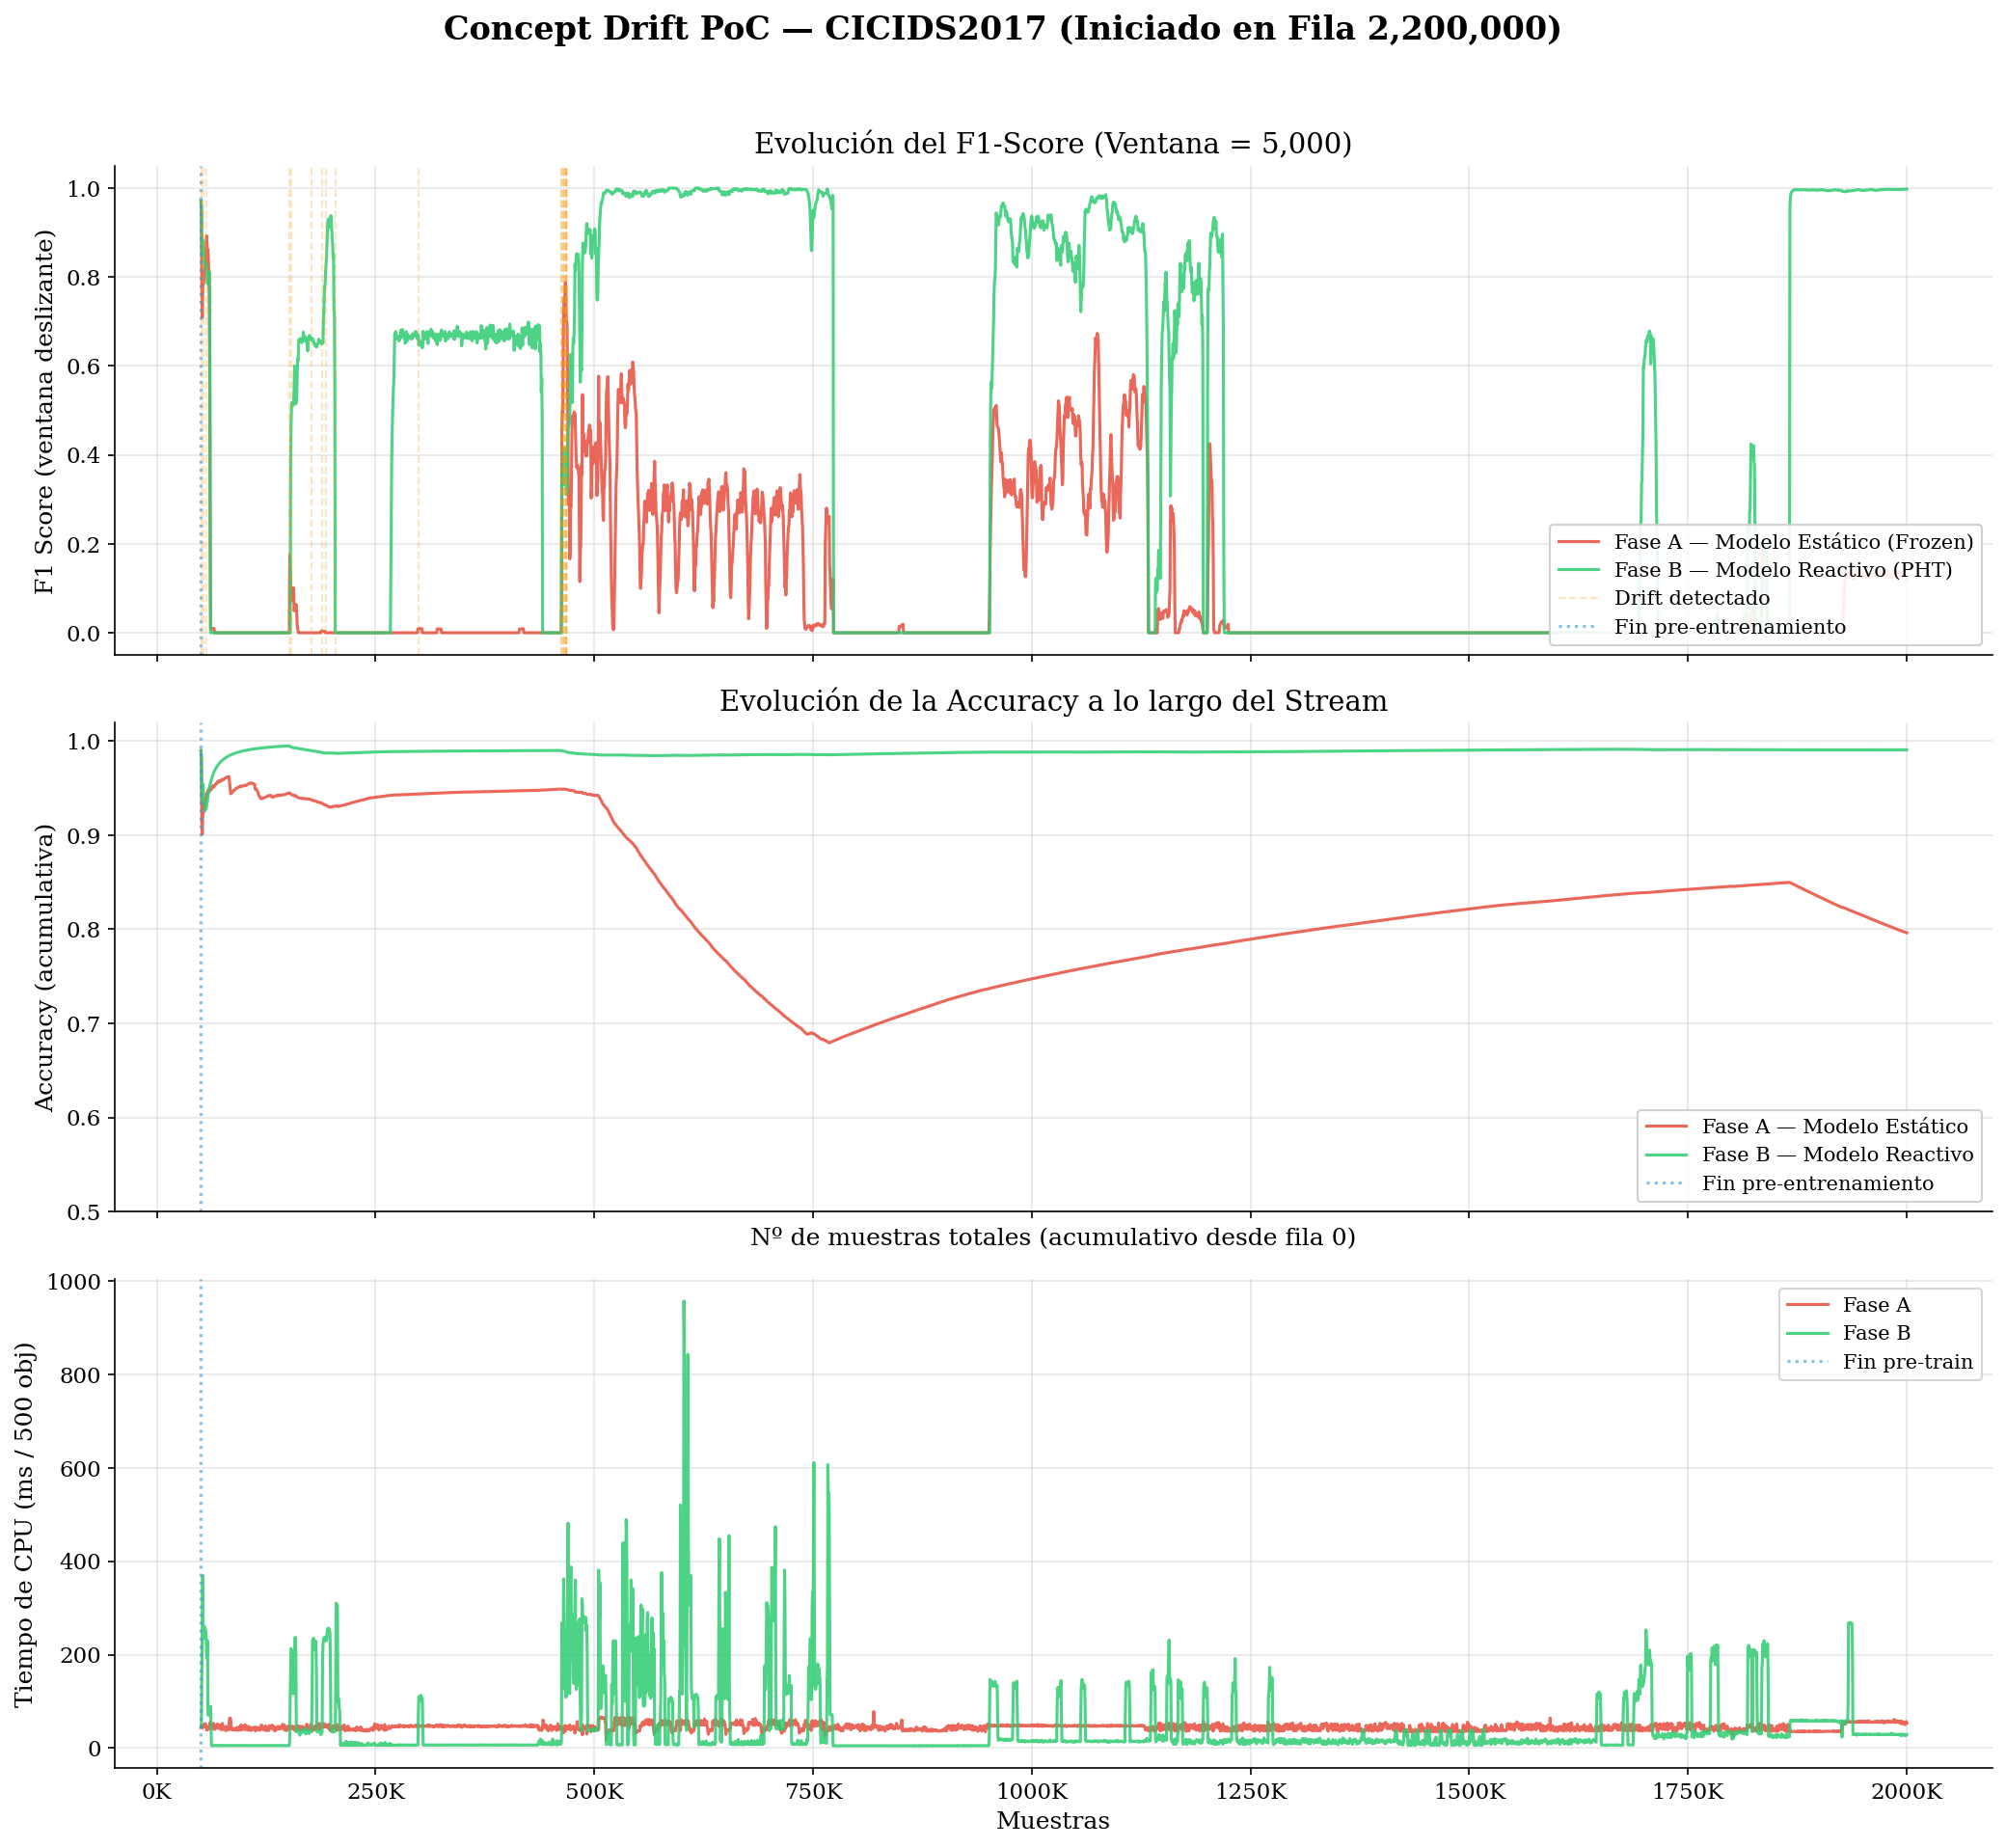


✅ Gráfica guardada en CONCEPT_DRIFT/concept_drift_results.png


In [7]:
# ════════════════════════════════════════════════════════════════
# 📊  Visualización — Comparativa Fase A vs Fase B
# ════════════════════════════════════════════════════════════════

plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'legend.fontsize': 10,
    'figure.dpi': 150,
    'savefig.dpi': 200,
    'axes.grid': True,
    'grid.alpha': 0.3,
})

fig, axes = plt.subplots(3, 1, figsize=(14, 13), sharex=True)
fig.suptitle("Concept Drift PoC — CICIDS2017 (Iniciado en Fila 2,200,000)",
             fontsize=16, fontweight='bold', y=0.98)

# ── Panel 1: F1 Score (Ventana Deslizante) ──
ax1 = axes[0]
ax1.plot(snap_x_a, snap_f1_a, color='#e74c3c', linewidth=1.5,
         alpha=0.85, label='Fase A — Modelo Estático (Frozen)')
ax1.plot(snap_x_b, snap_f1_b, color='#2ecc71', linewidth=1.5,
         alpha=0.85, label='Fase B — Modelo Reactivo (PHT)')

# Marcar primer drift relevante con línea vertical
for i, dp in enumerate(drift_points[:20]):
    ax1.axvline(x=dp, color='#f39c12', alpha=0.25, linewidth=1.0,
                linestyle='--', label='Drift detectado' if i == 0 else None)

ax1.axvline(x=N_PRETRAIN, color='#3498db', alpha=0.6, linewidth=1.5,
            linestyle=':', label=f'Fin pre-entrenamiento')

ax1.set_ylabel("F1 Score (ventana deslizante)")
ax1.set_title("Evolución del F1-Score (Ventana = 5,000)")
ax1.legend(loc='lower right', framealpha=0.9)
ax1.set_ylim(-0.05, 1.05)

# ── Panel 2: Accuracy (Acumulativa) ──
ax2 = axes[1]
ax2.plot(snap_x_a, snap_acc_a, color='#e74c3c', linewidth=1.5,
         alpha=0.85, label='Fase A — Modelo Estático')
ax2.plot(snap_x_b, snap_acc_b, color='#2ecc71', linewidth=1.5,
         alpha=0.85, label='Fase B — Modelo Reactivo')

ax2.axvline(x=N_PRETRAIN, color='#3498db', alpha=0.6, linewidth=1.5,
            linestyle=':', label=f'Fin pre-entrenamiento')

ax2.set_xlabel("Nº de muestras totales (acumulativo desde fila 0)")
ax2.set_ylabel("Accuracy (acumulativa)")
ax2.set_title("Evolución de la Accuracy a lo largo del Stream")
ax2.legend(loc='lower right', framealpha=0.9)
ax2.set_ylim(0.5, 1.02)

# Formatear eje X

ax3 = axes[2]
ax3.plot(snap_x_a, snap_time_a, color='#e74c3c', lw=1.5, alpha=0.85, label='Fase A')
ax3.plot(snap_x_b, snap_time_b, color='#2ecc71', lw=1.5, alpha=0.85, label='Fase B')
ax3.axvline(x=N_PRETRAIN, color='#3498db', alpha=0.6, lw=1.5, ls=':', label='Fin pre-train')
ax3.set_xlabel("Muestras")
ax3.set_ylabel("Tiempo de CPU (ms / 500 obj)")
ax3.legend(loc='upper right')

for ax in axes:
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'{x/1000:.0f}K'))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("/mnt/AI-DATA-SSD/alara/CiberIA_O1_A1/CONCEPT_DRIFT/concept_drift_results.png",
            bbox_inches='tight', facecolor='white')
plt.show()
print("\n✅ Gráfica guardada en CONCEPT_DRIFT/concept_drift_results.png")

In [ ]:
# ════════════════════════════════════════════════════════════════
# 💾  Guardar Resultados para Comparativa Posterior
# ════════════════════════════════════════════════════════════════
import numpy as np
np.savez('/mnt/AI-DATA-SSD/alara/CiberIA_O1_A1/CONCEPT_DRIFT/results_ab.npz',
         snap_x_a=snap_x_a, snap_f1_a=snap_f1_a, snap_acc_a=snap_acc_a, snap_time_a=snap_time_a,
         snap_x_b=snap_x_b, snap_f1_b=snap_f1_b, snap_acc_b=snap_acc_b, snap_time_b=snap_time_b,
         drift_points=drift_points,
         N_PRETRAIN=N_PRETRAIN)
print("✅ Datos de Fase A y B guardados en results_ab.npz")


In [8]:
# ════════════════════════════════════════════════════════════════
# 📋  Resumen del Experimento
# ════════════════════════════════════════════════════════════════

print("=" * 70)
print("  RESUMEN DEL ABLATION STUDY")
print("=" * 70)
print(f"  Fila de inicio en CSV:       {START_ROW:,}")
print(f"  Muestras pre-entrenamiento:  {N_PRETRAIN:,}")
print(f"  Muestras totales evaluadas:  {max(n_processed, n_processed_b):,}")
print(f"")
print(f"  ┌─────────────────────┬──────────┬──────────┐")
print(f"  │      Métrica        │  Fase A  │  Fase B  │")
print(f"  ├─────────────────────┼──────────┼──────────┤")
print(f"  │ Accuracy final      │  {acc_static.get():.4f}  │  {acc_reactive.get():.4f}  │")
print(f"  │ F1 rolling final    │  {f1_static.get():.4f}  │  {f1_reactive.get():.4f}  │")
print(f"  │ Drifts detectados   │    N/A   │  {n_drifts:>6}  │")
print(f"  └─────────────────────┴──────────┴──────────┘")
print(f"")
print("  💡 Distribución de etiquetas originales en esta porción:")
all_labels = label_dist_b if label_dist_b else label_dist
total = sum(all_labels.values())
for label, count in sorted(all_labels.items(), key=lambda x: -x[1]):
    pct = 100 * count / total
    print(f"    {label:<20s}: {count:>10,}  ({pct:5.2f}%)")
print("=" * 70)

  RESUMEN DEL ABLATION STUDY
  Fila de inicio en CSV:       540,000
  Muestras pre-entrenamiento:  50,000
  Muestras totales evaluadas:  2,000,000

  ┌─────────────────────┬──────────┬──────────┐
  │      Métrica        │  Fase A  │  Fase B  │
  ├─────────────────────┼──────────┼──────────┤
  │ Accuracy final      │  0.7963  │  0.9908  │
  │ F1 rolling final    │  0.1213  │  0.9977  │
  │ Drifts detectados   │    N/A   │      99  │
  └─────────────────────┴──────────┴──────────┘

  💡 Distribución de etiquetas originales en esta porción:
    BENIGN              :  1,599,330  (79.97%)
    DoS                 :    252,660  (12.63%)
    Port Scan           :    129,982  ( 6.50%)
    Brute Force         :     13,835  ( 0.69%)
    Web Attack          :      2,180  ( 0.11%)
    Bot                 :      1,966  ( 0.10%)
    Infiltration        :         36  ( 0.00%)
    Heartbleed          :         11  ( 0.00%)
